# Part 5 — Historical Test and Evaluation

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Evaluate the selected development specification and independently thresholded prior baseline once. All tables and figures are reconstructed from sealed prediction evidence. No estimator or alarm threshold is fitted here.

## 1. Repository and runtime
Use a fresh CPU runtime, Java 17 or later, and the pinned dependencies. Use the same Python and dependency versions for both Part 5 notebooks.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, shutil
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
java = shutil.which("java")
if java is None:
    raise RuntimeError("Java 17 or later is required")
os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
print(subprocess.run([java,"-version"],check=True,capture_output=True,text=True).stderr)
subprocess.run([sys.executable,"-m","pip","install","-r",str(REPO/"requirements.txt")],check=True)
sys.path.insert(0,str(REPO/'src'))
def command(action):
    proc = subprocess.Popen([sys.executable,str(REPO/'run_part5.py'),action,'--workspace',str(WORKSPACE)],cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in proc.stdout:
        print(line,end='',flush=True)
    if proc.wait()!=0:
        raise RuntimeError(f'Part 5 {action} failed; inspect diagnostics')

Git revision: e74142601962bf6646798e5564eb9d4ab56c271a
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



## 2. Mandatory offline validation
Run the complete test suite, including real Parquet and Spark integration. A failed or skipped test stops the pipeline.

In [2]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path('/content/part5_tests.xml')
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable,'-m','pytest','-q','-ra','--tb=short','--show-capture=no',f'--junitxml={result_path}','tests'],cwd=REPO,env=dict(os.environ,PYTEST_DISABLE_PLUGIN_AUTOLOAD='1',SPARK_LOCAL_IP='127.0.0.1',PYSPARK_PYTHON=sys.executable,MPLBACKEND='Agg'),capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
if not result_path.is_file(): raise RuntimeError('Missing pytest report')
cases=list(ET.parse(result_path).getroot().iter('testcase'))
problems=[(case,node) for case in cases for node in case if node.tag in ('failure','error','skipped')]
for case,node in problems:
    print(case.get('classname'),case.get('name'),node.tag,node.get('message'),node.text or '')
if result.returncode or not cases or problems: raise RuntimeError('Offline validation failed; inspect diagnostics')
TESTS_PASSED=True
print(f'Mandatory offline validation: PASS ({len(cases)} tests, zero skips)')

........................................................................ [ 54%]
............................................................             [100%]
----------------- generated xml file: /content/part5_tests.xml -----------------
132 passed in 292.55s (0:04:52)

Mandatory offline validation: PASS (132 tests, zero skips)


## 3. Verified upstream identities
Check the sealed Gold and Silver inventories and Bronze manifest identity. Development does not decode the historical test partitions.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
WORKSPACE=Path('/content/drive/MyDrive/11230945')
assert TESTS_PASSED
from fdic_ews.modelling.pipeline import upstream, evidence_path, verify_development, verify_oof
from fdic_ews.contracts import sha256
GOLD, gm, SILVER, IDENTITY = upstream(WORKSPACE)
EVIDENCE=evidence_path(WORKSPACE,IDENTITY)
ATTEMPT=EVIDENCE.parent/'test_attempt.json'
print('Verified upstream identities:',json.dumps(IDENTITY,indent=2))
print('Gold decision quarters:',gm['summary']['decision_quarters'])
print('Gold predictors:',gm['summary']['feature_count'])
print('Represented test-calendar failures:',gm['summary']['test_distinct_failure_certs_in_calendar_period'])
print('Evidence directory:',EVIDENCE)

Mounted at /content/drive
Verified upstream identities: {
  "gold": "de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780",
  "silver": "b6d91c7d0095b81e6200a0ae0940a103968c452046b168e446cd02089d323af0",
  "bronze": "e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e"
}
Gold decision quarters: 166
Gold predictors: 29
Represented test-calendar failures: 505
Evidence directory: /content/drive/MyDrive/11230945/modelling/de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780


## 4. Confirm the sealed development protocol
The Python and package versions must match the sealed environment before the first test attempt. Read the model, features, cost policy and thresholds; do not modify them.

In [4]:
import pandas as pd
import numpy as np
from IPython.display import display
from fdic_ews.modelling.pipeline import environment
DM=verify_development(EVIDENCE,IDENTITY)
S=DM['summary']; SELECTED=S['selected_model']
print('Selection:',SELECTED)
print('Locked thresholds:',S['thresholds'])
print('Cost policy:',json.dumps(S['cost_policy'],indent=2))
print('Development seal:',sha256(EVIDENCE/'development_manifest.json'))
print('Recorded runtime:',json.dumps(DM['environment'],indent=2))
if not ATTEMPT.exists():
    assert environment()==DM['environment'], 'Runtime mismatch: resolve before authorizing the test'

Selection: lightgbm_no_quality
Locked thresholds: {'lightgbm_no_quality': 0.03367313153323793, 'prior': 2.0}
Cost policy: {
  "c_fn": 4422.499999999997,
  "c_fp": 60.20999999999997,
  "conflicting_dated_cost_events": 0,
  "cutoff": "2007-12-31",
  "eligible_dated_cost_events": 0,
  "excluded_cost_records_by_vintage": 1910,
  "fallback_loss_fraction": 0.1,
  "median_development_assets": 60209.99999999997,
  "median_eligible_fdic_cost": null,
  "median_failed_event_assets": 44224.99999999997,
  "minimum_dated_cost_events": 20,
  "missed_cost_source": "assumed_10pct_of_median_failed_bank_assets",
  "positive_current_cost_events": 1910,
  "represented_development_events": 1976,
  "review_asset_fraction": 0.001,
  "unit": "USD thousands"
}
Development seal: 12532646188770d748eea1b494cb350410a23057887e552ba5568ec19c04072f
Recorded runtime: {
  "joblib": "1.5.2",
  "lightgbm": "4.6.0",
  "numpy": "2.2.6",
  "pandas": "2.2.3",
  "pyarrow": "21.0.0",
  "pyspark": "4.0.1",
  "python": "3.13.18",

## 5. Authorize the single historical evaluation
After checking Notebook 06, change `AUTHORIZE_HISTORICAL_TEST` to `True` for the first evaluation only. A workspace-wide marker is created before the test is decoded or scored. If a completed test exists, the cell verifies saved predictions instead. If an attempted test is incomplete, stop and document the failure; do not remove the marker.

In [6]:
AUTHORIZE_HISTORICAL_TEST = False  # Change to True once after inspecting the seal.
TEST=EVIDENCE/'test'
if ATTEMPT.exists():
    if not (TEST/'manifest.json').is_file():
        raise RuntimeError('Historical test was attempted but is incomplete. Preserve the marker and evidence; do not rescore.')
    print('Existing test evidence: read-only verification.')
else:
    if not AUTHORIZE_HISTORICAL_TEST:
        raise RuntimeError('Inspect the sealed development result, then explicitly authorize the single evaluation.')
    command('evaluate')
command('verify')
TM=json.loads((TEST/'manifest.json').read_text())
assert TM['state']=='VERIFIED'
print('Test state:',TM['state'])
print('Test seal SHA-256:',sha256(TEST/'manifest.json'))

{
  "status": "PASS",
  "path": "/content/drive/MyDrive/11230945/modelling/de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780",
  "state": "VERIFIED",
  "summary": {},
  "rows": 205672
}
{
  "status": "PASS",
  "path": "/content/drive/MyDrive/11230945/modelling/de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780",
  "state": "VERIFIED",
  "summary": {},
  "rows": 205672
}
Test state: VERIFIED
Test seal SHA-256: 8e6d5344d8a0bbb7fa56ff50be8f7b53796f89d6367cf8dc011ad72fae6298cd


## 6. Historical test ranking and operating performance
Report AP, ROC-AUC, Brier score, log loss and quarter-wise top-5% recall separately from operating metrics at the frozen threshold. The baseline has its own development-optimized threshold. No-alarm and all-alarm reference policies are computed without refitting.

**Table 1. Historical test ranking and probability diagnostics**

Model,Observations,Positives,Prevalence,AP,ROC-AUC,Brier score,Log loss,Top-5% recall
LightGBM (No Quality),"205,672","2,007",0.9758%,0.4686,0.9753,0.006909,0.027616,87.89%
Prior Baseline,"205,672","2,007",0.9758%,0.0098,0.5000,0.009670,0.055310,1.89%


**Table 2. Classification performance at frozen thresholds**

Model,Threshold,TP,FP,FN,TN,Precision,Recall,False-positive rate,Alert rate
LightGBM (No Quality),0.033673,"1,502","3,236",505,"200,429",31.70%,74.84%,1.59%,2.30%
Prior Baseline,2.000000,0,0,"2,007","203,665",—,0.00%,0.00%,0.00%


**Table 3. Modelled economic loss**

Model,False alarms,Missed failures,Modelled loss (USD thousands)
LightGBM (No Quality),"3,236",31,"331,937.06"
Prior Baseline,0,513,"2,268,742.50"


**Reference operating policies**

Reference policy,False alarms,Missed failures,Modelled loss (USD thousands)
No alarm,0,513,"2,268,742.50"
All alarm,"203,665",0,"12,262,669.65"


*Note: Economic losses are scenario-based estimates. A threshold of 2.0 denotes the no-alarm policy.*

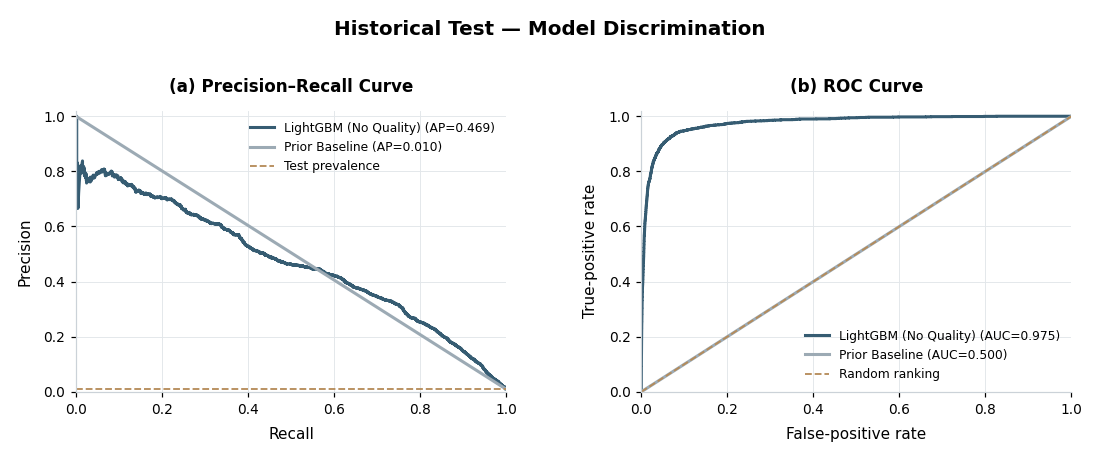

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pyarrow.parquet as pq

from io import BytesIO
from IPython.display import display, Markdown, HTML, Image
from sklearn.metrics import precision_recall_curve, roc_curve


# ============================================================
# Presentation settings
# ============================================================

PRIMARY = "#365C72"
SECONDARY = "#9CAAB4"
ACCENT = "#B58B59"
GRID = "#E2E6EA"

MODEL_LABELS = {
    SELECTED: "LightGBM (No Quality)",
    "prior": "Prior Baseline"
}

MODEL_COLORS = {
    SELECTED: PRIMARY,
    "prior": SECONDARY
}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 10,
    "axes.labelpad": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#CBD2D8",
    "legend.fontsize": 8,
    "legend.frameon": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9
})


def spacer(height=28):
    """Insert vertical spacing between notebook outputs."""
    display(HTML(
        f'<div style="height:{height}px;'
        f'min-height:{height}px;'
        'line-height:0;">&nbsp;</div>'
    ))


def display_table(df, title, labels=None, formats=None):
    """Render a formatted table without modifying evidence."""

    table = df.copy()

    if "model" in table.columns:
        table["model"] = table["model"].replace(MODEL_LABELS)

    if "policy" in table.columns:
        table["policy"] = table["policy"].replace({
            "no_alarm": "No alarm",
            "all_alarm": "All alarm"
        })

    spacer(28)

    display(Markdown(f"**{title}**"))

    styler = (
        table.style
        .format(formats or {}, na_rep="—")
        .hide(axis="index")
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("border-spacing", "0")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", PRIMARY),
                    ("color", "white"),
                    ("font-weight", "600"),
                    ("font-size", "11px"),
                    ("padding", "9px 12px"),
                    ("text-align", "center"),
                    ("white-space", "normal")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("font-size", "11px"),
                    ("padding", "8px 12px"),
                    ("color", "#243746"),
                    ("border-bottom", "1px solid #E2E6EA")
                ]
            },
            {
                "selector": "tbody tr:nth-child(odd)",
                "props": [
                    ("background-color", "#F2F5F7")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#FFFFFF")
                ]
            }
        ])
        .relabel_index(
            [labels.get(c, c) for c in table.columns]
            if labels else list(table.columns),
            axis="columns"
        )
    )

    display(styler)


def show_figure(fig, title):
    """Display a compact figure with consistent spacing."""

    fig.suptitle(
        title,
        fontsize=13,
        fontweight="bold"
    )

    fig.get_layout_engine().set(
        h_pad=0.18,
        w_pad=0.16,
        hspace=0.15,
        wspace=0.12
    )

    buffer = BytesIO()

    fig.savefig(
        buffer,
        format="png",
        dpi=110,
        facecolor="white"
    )

    plt.close(fig)

    spacer(32)

    display(Image(
        data=buffer.getvalue(),
        width=900
    ))

    buffer.close()

    spacer(24)


# ============================================================
# Load verified historical test evidence
# ============================================================

metrics = pd.read_csv(TEST / "test_metrics.csv")
refs = pd.read_csv(TEST / "reference_policies.csv")


# ============================================================
# Table 1. Ranking and probability diagnostics
# ============================================================

display_table(
    metrics[[
        "model", "rows", "positives", "prevalence",
        "ap", "roc_auc", "brier", "log_loss",
        "recall_top5pct_by_quarter"
    ]],
    "Table 1. Historical test ranking and probability diagnostics",
    labels={
        "model": "Model",
        "rows": "Observations",
        "positives": "Positives",
        "prevalence": "Prevalence",
        "ap": "AP",
        "roc_auc": "ROC-AUC",
        "brier": "Brier score",
        "log_loss": "Log loss",
        "recall_top5pct_by_quarter": "Top-5% recall"
    },
    formats={
        "rows": "{:,.0f}",
        "positives": "{:,.0f}",
        "prevalence": "{:.4%}",
        "ap": "{:.4f}",
        "roc_auc": "{:.4f}",
        "brier": "{:.6f}",
        "log_loss": "{:.6f}",
        "recall_top5pct_by_quarter": "{:.2%}"
    }
)


# ============================================================
# Table 2. Operating performance
# ============================================================

display_table(
    metrics[[
        "model", "threshold", "tp", "fp", "fn", "tn",
        "precision", "recall", "fpr", "alert_rate"
    ]],
    "Table 2. Classification performance at frozen thresholds",
    labels={
        "model": "Model",
        "threshold": "Threshold",
        "tp": "TP",
        "fp": "FP",
        "fn": "FN",
        "tn": "TN",
        "precision": "Precision",
        "recall": "Recall",
        "fpr": "False-positive rate",
        "alert_rate": "Alert rate"
    },
    formats={
        "threshold": "{:.6f}",
        **{
            c: "{:,.0f}"
            for c in ["tp", "fp", "fn", "tn"]
        },
        **{
            c: "{:.2%}"
            for c in [
                "precision", "recall",
                "fpr", "alert_rate"
            ]
        }
    }
)


# ============================================================
# Table 3. Modelled economic loss
# ============================================================

cost_labels = {
    "model": "Model",
    "policy": "Reference policy",
    "fp": "False alarms",
    "missed_events": "Missed failures",
    "loss_usd_thousands": "Modelled loss (USD thousands)"
}

cost_formats = {
    "fp": "{:,.0f}",
    "missed_events": "{:,.0f}",
    "loss_usd_thousands": "{:,.2f}"
}

display_table(
    metrics[[
        "model", "fp", "missed_events",
        "loss_usd_thousands"
    ]],
    "Table 3. Modelled economic loss",
    labels=cost_labels,
    formats=cost_formats
)

display_table(
    refs[[
        "policy", "fp", "missed_events",
        "loss_usd_thousands"
    ]],
    "Reference operating policies",
    labels=cost_labels,
    formats=cost_formats
)

spacer(12)

display(Markdown(
    "*Note: Economic losses are scenario-based estimates. "
    "A threshold of 2.0 denotes the no-alarm policy.*"
))


# ============================================================
# Load saved predictions
# ============================================================

predictions = {
    name: pq.ParquetFile(
        TEST / f"predictions_{name}.parquet"
    ).read().to_pandas()
    for name in [SELECTED, "prior"]
}


# ============================================================
# Figure 1. Model discrimination
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.2),
    layout="constrained"
)

for name, p in predictions.items():

    precision, recall, _ = precision_recall_curve(
        p.Y_FAIL_4Q, p.score
    )

    fpr, tpr, _ = roc_curve(
        p.Y_FAIL_4Q, p.score
    )

    row = metrics.loc[
        metrics.model.eq(name)
    ].iloc[0]

    axes[0].plot(
        recall,
        precision,
        color=MODEL_COLORS[name],
        linewidth=2,
        label=(
            f"{MODEL_LABELS[name]} "
            f"(AP={row.ap:.3f})"
        )
    )

    axes[1].plot(
        fpr,
        tpr,
        color=MODEL_COLORS[name],
        linewidth=2,
        label=(
            f"{MODEL_LABELS[name]} "
            f"(AUC={row.roc_auc:.3f})"
        )
    )

axes[0].axhline(
    float(metrics.prevalence.iloc[0]),
    color=ACCENT,
    linestyle="--",
    linewidth=1.2,
    label="Test prevalence"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    color=ACCENT,
    linestyle="--",
    linewidth=1.2,
    label="Random ranking"
)

axes[0].set(
    title="(a) Precision–Recall Curve",
    xlabel="Recall",
    ylabel="Precision"
)

axes[1].set(
    title="(b) ROC Curve",
    xlabel="False-positive rate",
    ylabel="True-positive rate"
)

for ax in axes:
    ax.set(
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    ax.grid(color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(loc="best")

show_figure(
    fig,
    "Historical Test — Model Discrimination"
)


## 7. Event detection and warning lead time
Count distinct CERT–failure-date events once. The lead time is the number of days from the earliest positive alert to the failure; it is conditional on detection. Distinguish failures occurring within the test calendar from the events represented through the final test outcome horizon.

**Table 4. Event-level outcomes through the test horizons**

Model,Failure events,Detected,Missed,Event recall,Median lead time (days),Lead time ≥ 90 days
LightGBM (No Quality),513,482,31,93.96%,282.5,436
Prior Baseline,513,0,513,0.00%,—,0


**Table 5. Failure events within the historical test calendar**

Model,Represented events,Distinct institutions,Detected events,Event recall,Median lead time (days)
LightGBM (No Quality),505,505,475,94.06%,282.0
Prior Baseline,505,505,0,0.00%,—


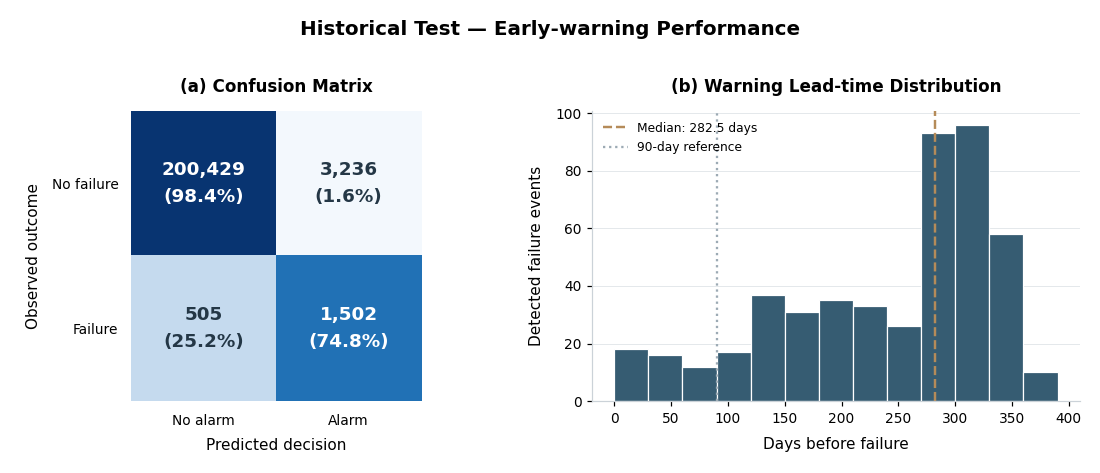

*Note: Confusion-matrix percentages are normalized by observed class. Warning lead time is conditional on event detection and is measured from the earliest correct alarm to the failure date.*

In [16]:

# ============================================================
# Table 4. Event-level evaluation
# ============================================================

event_columns = [
    "model",
    "events",
    "detected_events",
    "missed_events",
    "event_recall",
    "median_lead_days",
    "lead_at_least_90_days"
]

display_table(
    metrics[event_columns],
    "Table 4. Event-level outcomes through the test horizons",
    labels={
        "model": "Model",
        "events": "Failure events",
        "detected_events": "Detected",
        "missed_events": "Missed",
        "event_recall": "Event recall",
        "median_lead_days": "Median lead time (days)",
        "lead_at_least_90_days": "Lead time ≥ 90 days"
    },
    formats={
        **{
            c: "{:,.0f}"
            for c in [
                "events",
                "detected_events",
                "missed_events",
                "lead_at_least_90_days"
            ]
        },
        "event_recall": "{:.2%}",
        "median_lead_days": "{:.1f}"
    }
)


# ============================================================
# Table 5. Historical test-calendar events
# ============================================================

calendar = pd.read_csv(
    TEST / "test_calendar_events.csv"
)

display_table(
    calendar,
    "Table 5. Failure events within the historical test calendar",
    labels={
        "model": "Model",
        "represented_events": "Represented events",
        "distinct_certs": "Distinct institutions",
        "detected_events": "Detected events",
        "event_recall": "Event recall",
        "median_lead_days": "Median lead time (days)"
    },
    formats={
        "represented_events": "{:,.0f}",
        "distinct_certs": "{:,.0f}",
        "detected_events": "{:,.0f}",
        "event_recall": "{:.2%}",
        "median_lead_days": "{:.1f}"
    }
)


# ============================================================
# Load saved event evidence
# ============================================================

events = pd.read_csv(
    TEST / f"events_{SELECTED}.csv"
)

r = metrics.loc[
    metrics.model.eq(SELECTED)
].iloc[0]


# ============================================================
# Confusion matrix
# ============================================================

cm = np.array([
    [r.tn, r.fp],
    [r.fn, r.tp]
], dtype=int)

row_total = cm.sum(
    axis=1,
    keepdims=True
)

cm_pct = np.divide(
    cm,
    row_total,
    out=np.zeros_like(cm, dtype=float),
    where=row_total != 0
)


# ============================================================
# Figure 2. Early-warning performance
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.3),
    gridspec_kw={
        "width_ratios": [1, 1.3]
    },
    layout="constrained"
)


# ------------------------------------------------------------
# Panel A. Confusion matrix
# ------------------------------------------------------------

ax = axes[0]

ax.imshow(
    cm_pct,
    cmap="Blues",
    vmin=0,
    vmax=1
)

for i in range(2):
    for j in range(2):

        text_color = (
            "white"
            if cm_pct[i, j] >= 0.55
            else "#243746"
        )

        ax.text(
            j,
            i,
            f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=text_color,
            linespacing=1.6
        )

ax.set(
    title="(a) Confusion Matrix",
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["No alarm", "Alarm"],
    yticklabels=["No failure", "Failure"],
    xlabel="Predicted decision",
    ylabel="Observed outcome"
)

ax.tick_params(length=0, pad=8)

for spine in ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# Panel B. Warning lead-time distribution
# ------------------------------------------------------------

ax = axes[1]

lead = events.loc[
    events.detected.eq(True),
    "lead_days"
].dropna()

if not lead.empty:

    bins = np.arange(0, 400, 30)

    ax.hist(
        lead,
        bins=bins,
        color=PRIMARY,
        edgecolor="white",
        linewidth=0.8
    )

    median_lead = float(lead.median())

    ax.axvline(
        median_lead,
        color=ACCENT,
        linestyle="--",
        linewidth=1.6,
        label=f"Median: {median_lead:.1f} days"
    )

    ax.axvline(
        90,
        color=SECONDARY,
        linestyle=":",
        linewidth=1.5,
        label="90-day reference"
    )

    ax.legend(loc="upper left")

else:

    ax.text(
        0.5,
        0.5,
        "No detected failure events",
        transform=ax.transAxes,
        ha="center",
        va="center"
    )

ax.set(
    title="(b) Warning Lead-time Distribution",
    xlabel="Days before failure",
    ylabel="Detected failure events"
)

ax.grid(
    axis="y",
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)

show_figure(
    fig,
    "Historical Test — Early-warning Performance"
)

display(Markdown(
    "*Note: Confusion-matrix percentages are normalized by "
    "observed class. Warning lead time is conditional on "
    "event detection and is measured from the earliest "
    "correct alarm to the failure date.*"
))

spacer(20)


## 8. Calibration and regime diagnostics
Reliability bins are descriptive; no calibration is fitted on the test. Annual decision-period metrics describe temporal heterogeneity. Events can be represented in multiple decision years, so annual event counts and economic losses are not additive.

**Table 6. Annual decision-period diagnostics**

Year,Model,Observations,Positives,Prevalence,AP,ROC-AUC,Row recall,Event recall,False alarms,Missed events
2008,LightGBM (No Quality),"32,955",357,1.0833%,0.3902,0.9541,34.73%,47.24%,98,86
2008,Prior Baseline,"32,955",357,1.0833%,0.0108,0.5000,0.00%,0.00%,0,163
2009,LightGBM (No Quality),"32,114",670,2.0863%,0.6356,0.9718,71.49%,87.32%,441,35
2009,Prior Baseline,"32,114",670,2.0863%,0.0209,0.5000,0.00%,0.00%,0,276
2010,LightGBM (No Quality),"30,640",457,1.4915%,0.6006,0.9811,90.15%,95.67%,790,9
2010,Prior Baseline,"30,640",457,1.4915%,0.0149,0.5000,0.00%,0.00%,0,208
2011,LightGBM (No Quality),"29,416",269,0.9145%,0.5149,0.9917,95.17%,99.15%,773,1
2011,Prior Baseline,"29,416",269,0.9145%,0.0091,0.5000,0.00%,0.00%,0,117
2012,LightGBM (No Quality),"28,110",129,0.4589%,0.4178,0.9952,97.67%,100.00%,558,0
2012,Prior Baseline,"28,110",129,0.4589%,0.0046,0.5000,0.00%,0.00%,0,59


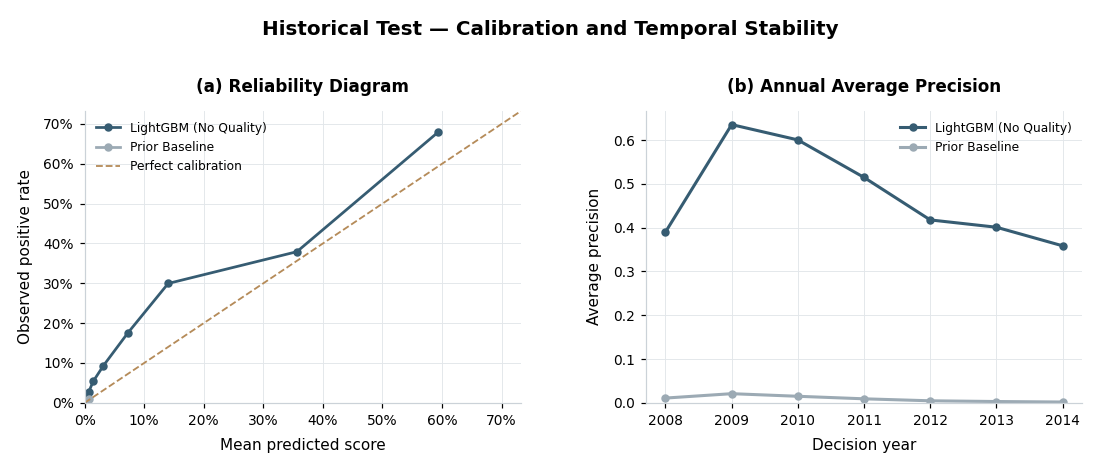

*Note: Reliability bins are descriptive and no calibration model is fitted on historical test data. Annual AP is affected by changes in failure prevalence. Failure events may appear in multiple decision years; annual event counts and economic losses are therefore not additive.*

In [17]:

# ============================================================
# Table 6. Annual decision-period diagnostics
# ============================================================

annual = pd.read_csv(
    TEST / "annual_metrics.csv"
)

annual = annual.sort_values(
    ["year", "model"]
).reset_index(drop=True)

display_table(
    annual[[
        "year",
        "model",
        "rows",
        "positives",
        "prevalence",
        "ap",
        "roc_auc",
        "recall",
        "event_recall",
        "fp",
        "missed_events"
    ]],
    "Table 6. Annual decision-period diagnostics",
    labels={
        "year": "Year",
        "model": "Model",
        "rows": "Observations",
        "positives": "Positives",
        "prevalence": "Prevalence",
        "ap": "AP",
        "roc_auc": "ROC-AUC",
        "recall": "Row recall",
        "event_recall": "Event recall",
        "fp": "False alarms",
        "missed_events": "Missed events"
    },
    formats={
        "year": "{:.0f}",
        **{
            c: "{:,.0f}"
            for c in [
                "rows",
                "positives",
                "fp",
                "missed_events"
            ]
        },
        "prevalence": "{:.4%}",
        "ap": "{:.4f}",
        "roc_auc": "{:.4f}",
        "recall": "{:.2%}",
        "event_recall": "{:.2%}"
    }
)


# ============================================================
# Load saved calibration evidence
# ============================================================

calibration_data = {
    name: pd.read_csv(
        TEST / f"calibration_{name}.csv"
    ).sort_values("mean_score")
    for name in [SELECTED, "prior"]
}


# ============================================================
# Figure 3. Calibration and temporal stability
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.3),
    layout="constrained"
)


# ------------------------------------------------------------
# Panel A. Reliability diagram
# ------------------------------------------------------------

ax = axes[0]

calibration_max = 0.0

for name, cal in calibration_data.items():

    ax.plot(
        cal.mean_score,
        cal.observed_rate,
        color=MODEL_COLORS[name],
        marker="o",
        markersize=4.5,
        linewidth=1.8,
        label=MODEL_LABELS[name]
    )

    calibration_max = max(
        calibration_max,
        float(cal.mean_score.max()),
        float(cal.observed_rate.max())
    )

upper = min(
    1.02,
    max(0.05, calibration_max * 1.08)
)

ax.plot(
    [0, upper],
    [0, upper],
    color=ACCENT,
    linestyle="--",
    linewidth=1.2,
    label="Perfect calibration"
)

ax.set(
    title="(a) Reliability Diagram",
    xlabel="Mean predicted score",
    ylabel="Observed positive rate",
    xlim=(0, upper),
    ylim=(0, upper)
)

ax.xaxis.set_major_formatter(
    mtick.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(
        xmax=1,
        decimals=0
    )
)

ax.grid(
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.legend(loc="best")


# ------------------------------------------------------------
# Panel B. Annual average precision
# ------------------------------------------------------------

ax = axes[1]

for name in [SELECTED, "prior"]:

    group = annual.loc[
        annual.model.eq(name)
    ].sort_values("year")

    ax.plot(
        group.year,
        group.ap,
        color=MODEL_COLORS[name],
        marker="o",
        markersize=4.5,
        linewidth=2,
        label=MODEL_LABELS[name]
    )

ax.set(
    title="(b) Annual Average Precision",
    xlabel="Decision year",
    ylabel="Average precision"
)

ax.set_xticks(
    sorted(annual.year.unique())
)

ax.set_ylim(bottom=0)

ax.grid(
    color=GRID,
    linewidth=0.6
)

ax.set_axisbelow(True)
ax.legend(loc="best")

show_figure(
    fig,
    "Historical Test — Calibration and Temporal Stability"
)

display(Markdown(
    "*Note: Reliability bins are descriptive and no calibration "
    "model is fitted on historical test data. Annual AP is "
    "affected by changes in failure prevalence. Failure events "
    "may appear in multiple decision years; annual event counts "
    "and economic losses are therefore not additive.*"
))

spacer(20)


## 9. Verification and conclusion handoff
The test is closed. Reopening the notebook must only verify saved evidence. Interpretation is limited to the fixed historical period, adjudicable outcomes, assumed information availability and proxy economic costs. Save this notebook with its outputs; do not revise model choices from test results.

In [18]:
print('Development seal:',sha256(EVIDENCE/'development_manifest.json'))
print('Workspace attempt marker:',ATTEMPT)
print('Test seal:',sha256(TEST/'manifest.json'))
print('Test rows:',TM['rows'])
print('Selected model:',SELECTED)
print('Status: VERIFIED — saved prediction evidence; no further test scoring')

Development seal: 12532646188770d748eea1b494cb350410a23057887e552ba5568ec19c04072f
Workspace attempt marker: /content/drive/MyDrive/11230945/modelling/test_attempt.json
Test seal: 8e6d5344d8a0bbb7fa56ff50be8f7b53796f89d6367cf8dc011ad72fae6298cd
Test rows: 205672
Selected model: lightgbm_no_quality
Status: VERIFIED — saved prediction evidence; no further test scoring
